# 04 – Feature Selection

Goal: In this notebook, we look for the features that matter most for detecting phishing, and we check if we can keep the same performance with fewer features. We compare three types of feature selection methods:
- Filter: mutual information.
- Wrapper: recursive feature elimination (RFE).
- Embedded: L1 logistic regression (Lasso) and tree importance.

We only use the training set, and every selection step is placed in a Pipeline to avoid data leakage.

In [1]:
import time
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
DATA_DIR = Path("../data")
FIG_DIR = Path("../figures"); FIG_DIR.mkdir(exist_ok=True)

train = pd.read_csv(DATA_DIR / "train.csv")
X_train, y_train = train.drop(columns="class"), train["class"]
FEATURES = list(X_train.columns)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Mutual information for discrete features (values -1/0/1)
mi_score = partial(mutual_info_classif, discrete_features=True, random_state=SEED)

# Final classifier: best model of notebook 03 (Gradient Boosting, tuned hyperparameters)
def make_clf():
    return HistGradientBoostingClassifier(learning_rate=0.1, max_iter=200, max_depth=6,
                                          l2_regularization=0.0, random_state=SEED)

def cv_scores(pipe):
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "f1", "recall"])
    return {m: r["test_" + m].mean() for m in ["roc_auc", "f1", "recall"]}

ref = cv_scores(Pipeline([("clf", make_clf())]))
print("All 30 features:", {k: round(v, 3) for k, v in ref.items()})

All 30 features: {'roc_auc': np.float64(0.993), 'f1': np.float64(0.951), 'recall': np.float64(0.948)}


## 1. Filter – mutual information
We keep the k features that share the most information with the target, and we test different values of k.

In [2]:
K_LIST = [2, 5, 10, 15, 20, 30]
filter_res = {}
for k in K_LIST:
    pipe = Pipeline([("select", SelectKBest(mi_score, k=k)), ("clf", make_clf())])
    filter_res[k] = cv_scores(pipe)
filter_res = pd.DataFrame(filter_res).T.round(3)
filter_res

,roc_auc,f1,recall
2,0.953,0.906,0.911
5,0.978,0.929,0.940
10,0.984,0.937,0.935
15,0.988,0.939,0.937
20,0.990,0.949,0.949
30,0.993,0.951,0.948


## 2. Wrapper – recursive feature elimination (RFE)
RFE trains a logistic regression, removes the least useful feature, and repeats until only k features are left. We then use these features with Gradient Boosting.

In [3]:
t0 = time.time()
rfe_res = {}
for k in K_LIST:
    pipe = Pipeline([("select", RFE(LogisticRegression(max_iter=1000), n_features_to_select=k)),
                     ("clf", make_clf())])
    rfe_res[k] = cv_scores(pipe)
rfe_res = pd.DataFrame(rfe_res).T.round(3)
print(f"RFE time: {time.time() - t0:.1f}s")
rfe_res

RFE time: 25.2s


,roc_auc,f1,recall
2,0.894,0.791,0.657
5,0.977,0.917,0.893
10,0.985,0.940,0.940
15,0.988,0.941,0.937
20,0.991,0.951,0.945
30,0.993,0.951,0.948


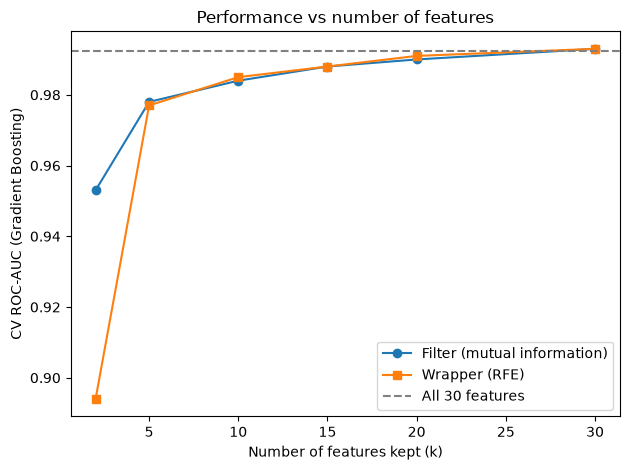

In [4]:
plt.plot(filter_res.index, filter_res["roc_auc"], "o-", label="Filter (mutual information)")
plt.plot(rfe_res.index, rfe_res["roc_auc"], "s-", label="Wrapper (RFE)")
plt.axhline(ref["roc_auc"], ls="--", color="gray", label="All 30 features")
plt.xlabel("Number of features kept (k)"); plt.ylabel("CV ROC-AUC (Gradient Boosting)")
plt.title("Performance vs number of features"); plt.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "fs_filter_vs_wrapper.png", dpi=150); plt.show()

## 3. Embedded – L1-penalised logistic regression (Lasso)
The L1 penalty sets some coefficients to zero, which removes the corresponding features. The smaller C is, the stronger the penalty, and the fewer features we keep. Note: penalty="l1" no longer works in recent versions of scikit-learn, so we use l1_ratio=1 instead.

In [5]:
def l1_logreg(C):
    return LogisticRegression(l1_ratio=1, solver="liblinear", C=C, max_iter=1000)

l1_res = {}
for C in [0.01, 0.03, 0.1, 0.3, 1]:
    n_kept = SelectFromModel(l1_logreg(C)).fit(X_train, y_train).get_support().sum()
    pipe = Pipeline([("select", SelectFromModel(l1_logreg(C))), ("clf", make_clf())])
    l1_res[C] = {"n_features": n_kept, **cv_scores(pipe)}
l1_res = pd.DataFrame(l1_res).T
l1_res["n_features"] = l1_res["n_features"].astype(int)
l1_res.round(3)

,n_features,roc_auc,f1,recall
0.01,9,0.985,0.936,0.939
0.03,16,0.987,0.935,0.933
0.10,23,0.991,0.947,0.940
0.30,29,0.992,0.950,0.945
1.00,30,0.992,0.951,0.949


## 4. Stability of the L1 selection (bootstrap)
We train the L1 model 50 times on random samples of the training set, and we count how often each feature is selected. A useful and stable feature is selected almost every time.

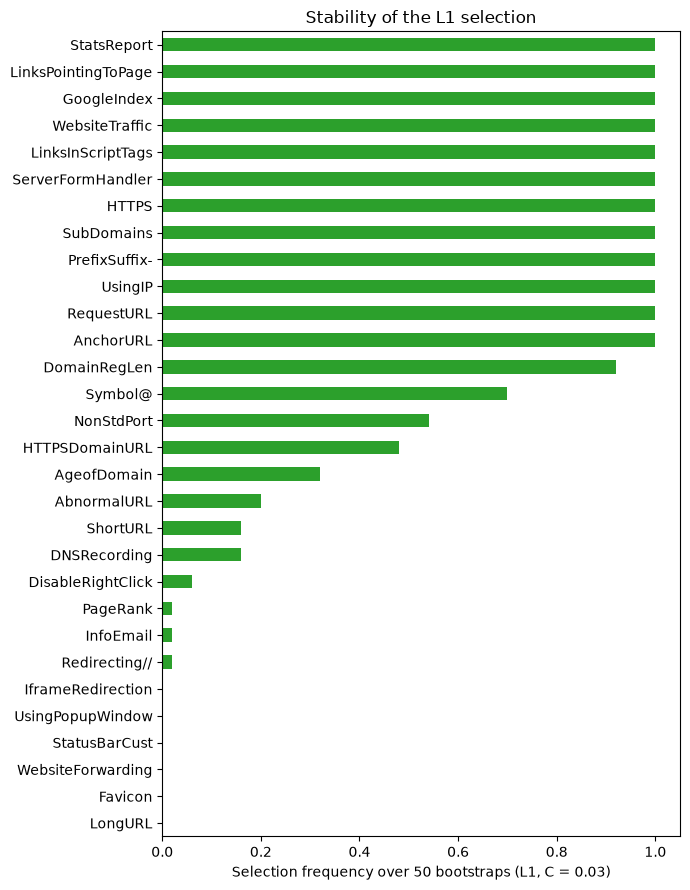

In [6]:
rng = np.random.RandomState(SEED)
C_STAB = 0.03
counts = np.zeros(len(FEATURES))
for _ in range(50):
    idx = rng.choice(len(X_train), len(X_train), replace=True)
    sel = SelectFromModel(l1_logreg(C_STAB)).fit(X_train.iloc[idx], y_train.iloc[idx])
    counts += sel.get_support()
stability = pd.Series(counts / 50, index=FEATURES).sort_values()

ax = stability.plot.barh(figsize=(7, 9), color="tab:green")
ax.set_xlabel(f"Selection frequency over 50 bootstraps (L1, C = {C_STAB})")
ax.set_title("Stability of the L1 selection")
plt.tight_layout(); plt.savefig(FIG_DIR / "fs_l1_stability.png", dpi=150); plt.show()

## 5. Embedded – importance in the Gradient Boosting model
We shuffle the values of one feature and measure how much the ROC-AUC drops. The bigger the drop, the more important the feature. We compute this on data the model did not see during training.

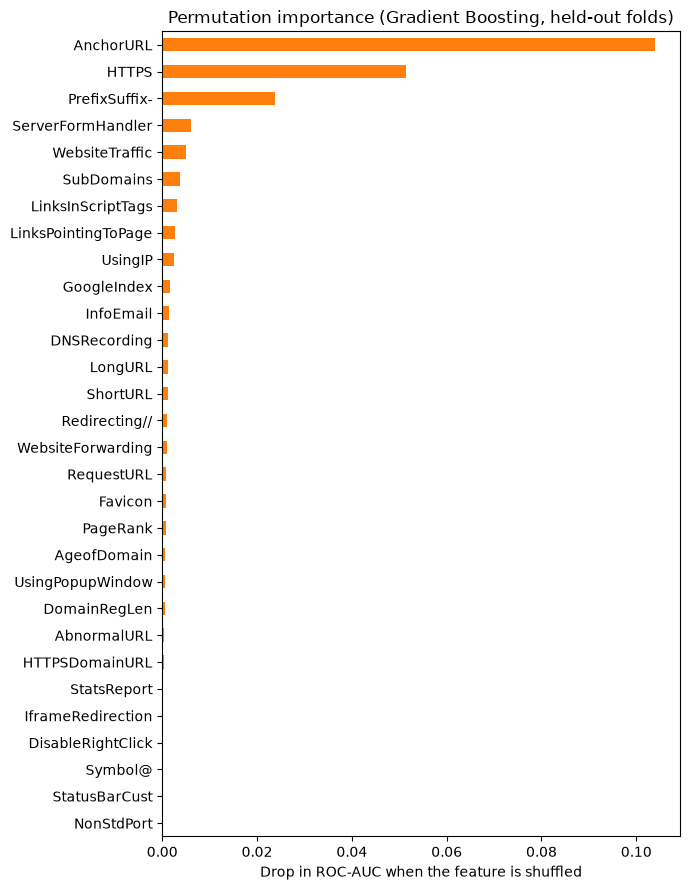

In [7]:
perm = np.zeros(len(FEATURES))
for tr, va in cv.split(X_train, y_train):
    model = make_clf().fit(X_train.iloc[tr], y_train.iloc[tr])
    r = permutation_importance(model, X_train.iloc[va], y_train.iloc[va], scoring="roc_auc",
                               n_repeats=5, random_state=SEED)
    perm += r.importances_mean / cv.get_n_splits()
perm = pd.Series(perm, index=FEATURES).sort_values()

ax = perm.plot.barh(figsize=(7, 9), color="tab:orange")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title("Permutation importance (Gradient Boosting, held-out folds)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fs_permutation_importance.png", dpi=150); plt.show()

## 6. Final ranking of the features
We combine the results of three methods (mutual information, L1 stability and permutation importance) to get a final ranking of the features.

In [8]:
mi_full = pd.Series(mi_score(X_train, y_train), index=FEATURES)
ranking = pd.DataFrame({
    "mutual_info": mi_full,
    "l1_stability": stability,
    "permutation_importance": perm,
})
ranking["mean_rank"] = ranking.rank(ascending=False).mean(axis=1)
ranking = ranking.sort_values("mean_rank")
ranking.round(3).head(15)

,mutual_info,l1_stability,permutation_importance,mean_rank
AnchorURL,0.310,1.00,0.104,3.167
HTTPS,0.340,1.00,0.051,3.167
PrefixSuffix-,0.094,1.00,0.024,4.167
ServerFormHandler,0.042,1.00,0.006,5.500
SubDomains,0.073,1.00,0.004,5.500
WebsiteTraffic,0.059,1.00,0.005,5.500
LinksInScriptTags,0.035,1.00,0.003,6.833
LinksPointingToPage,0.007,1.00,0.003,8.500
GoogleIndex,0.008,1.00,0.002,8.833
UsingIP,0.005,1.00,0.002,9.833


## 7. Data leakage check 
Here we test what happens if we select the features before cross-validation, on the whole training set. In this case, the validation data has already been used to choose the features, so the score is too optimistic.

In [9]:
k = 10
selector = SelectKBest(mi_score, k=k).fit(X_train, y_train)       # WRONG: selection on all data
leaky = cross_validate(make_clf(), X_train.loc[:, selector.get_support()], y_train,
                       cv=cv, scoring="roc_auc")["test_score"].mean()
correct = filter_res.loc[k, "roc_auc"]                              # selection inside the Pipeline
print(f"k = {k} | selection before CV (leaky): {leaky:.4f} | inside Pipeline (correct): {correct:.4f}")

k = 10 | selection before CV (leaky): 0.9850 | inside Pipeline (correct): 0.9840


The difference is small here, because we have many more websites than features. The problem is much bigger when there are more features than samples. We still keep the selection inside the Pipeline, because it is the correct way to do it.

## Conclusions
- With 20 features, we get almost the same ROC-AUC as with all 30 (0.990 vs 0.993). With 10 features it drops to 0.984, and with 2 features to 0.95 or less. The last features bring little, but the model still uses many small signals.
- The same features come first with every method: AnchorURL, HTTPS and PrefixSuffix-, then ServerFormHandler, SubDomains and WebsiteTraffic. They are the main signs of phishing in this dataset.
- With very few features, the filter works better than RFE (0.95 vs 0.89 with 2 features). From 10 features, both give similar results, but RFE is slower.
- Selecting features before cross-validation gives a slightly too optimistic score, but the effect is small here.
- Feature selection does not improve the score, but it makes the model simpler and easier to explain.
- In week 4, we will decide whether to keep all features or fewer, before testing on the test set.